# Equations used in the code
## Pandolf equation
$$M = 1.5 W + 2.0 (W + L)(L/W)^2 + η(W + L)[1.5 V^2 + 0.35 VG]$$

- M = metabolic rate, watts; 
- W = subject weight, kg; 
- L = load carried, kg; 
- V = walking speed, m/s; 
- G = grade, %; 
- η = terrain factor (terrain factor: 1.0).
## Watts to calories
$$1W = 1J / s$$
$$1 kcal = 4184 J$$
## LCDA (Load Carriage Decision Aid)
$$L_{Bp} = L / W$$
$$M_{Rest} = 500 + 22 * (W * 0.8)$$
$$M_{Grade}(W*kg^{−1})=34SG(1−1.05^{1−1.10G^{3.2}})$$
$$M(Watt*kg^{−1}) = M_{Rest}​+[0.19+η(1.78S^{0.58}+0.27S^4+ M_{Grade})](1+1.96L_{Bp}^{1.36}​)$$
- W is body mass ($kg$)
- S is Speed ($m*s^{-1}$)
- G is Grade ($100*rise/run$)
- L is Load ($kg$)
- η is terrain factor
- $M_{Grade}$ has to be per kg, so is divide by W
- $M_{Rest}$ uses cunningham equation, but doesn't specify unit. CE gives kcal/day. M is $Watt*kg^{-1}$, so the assumption is that CE needs to be converted to $Watt*kg^{-1}$ too.
- $M_{Rest}$ uses lean body mass, I have assumed a body fat of 30% for a female. Impact is only 2-3kcal per hour.


$\tiny LOONEY, DAVID P.1; LAVOIE, ELIZABETH M.1,2; VANGALA, SAI V.1; HOLDEN, LUCAS D.1,2; FIGUEIREDO, PETER S.1,2; FRIEDL, KARL E.1; FRYKMAN, PETER N.1; HANCOCK, JASON W.1; MONTAIN, SCOTT J.1; PRYOR, J. LUKE3; SANTEE, WILLIAM R.1; POTTER, ADAM W.1. Modeling the Metabolic Costs of Heavy Military Backpacking. Medicine \& Science in Sports \& Exercise 54(4):p 646-654, April 2022. | DOI: 10.1249/MSS.0000000000002833$

### Issues: 
The formula given in the above paper does not work for negative slope values. I referred to the paper that they reference and the formula is different there. I have inplemented this formula from that paper, which gives sensible results, although they need to be verified:
$$M_{Grade}(W*kg^{−1})=1.44 + 1.94S^{0.43}+0.24S^4+0.34SG(1-1.05^{1-1.1^{G+32}})$$

$\tiny LOONEY, DAVID P.; SANTEE, WILLIAM R.; HANSEN, ERIC O.; BONVENTRE, PETER J.; CHALMERS, CHRISTOPHER R.; POTTER, ADAM W.. Estimating Energy Expenditure during Level, Uphill, and Downhill Walking. Medicine \& Science in Sports \& Exercise 51(9):p 1954-1960, September 2019. | DOI: 10.1249/MSS.0000000000002002 $

## Naismith
Allow one hour for every five kilometres walked. Add one hour for every 600 metres of ascent.

$$t = (d_{km} / 5) + (e_m / 600)$$

## Wood et al
Updated formula based on UK GPS data and high res dem

$$v = exp(a + b\phi + c\theta + d\theta^2)$$

- v = walking speed (km/h)
- $\phi$ = hill slope angle (degrees)
- $\theta$ = walking slope angle (degrees)

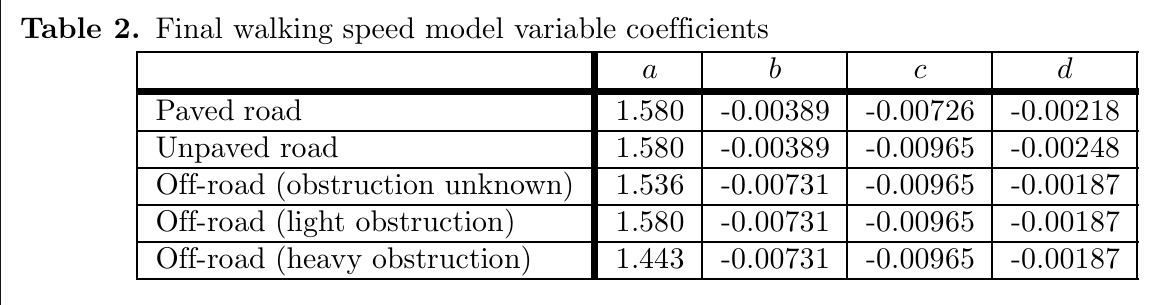

$\tiny Wood A, Mackaness W, Simpson TI, Armstrong JD (2023) Improved prediction of hiking speeds using a data driven approach. PLOS ONE 18(12): e0295848. doi.org/10.1371/journal.pone.0295848 $


In [1]:
import pandas as pd
import numpy as np
import re
import json
from datetime import datetime
from pathlib import Path
# fixing a VSCode startup issue with matplotlib
import os
conda_prefix = os.environ.get('CONDA_PREFIX')
if conda_prefix:
    extra_paths = [
        Path(conda_prefix) / 'Library' / 'mingw-w64' / 'bin',
        Path(conda_prefix) / 'Library' / 'usr' / 'bin',
        Path(conda_prefix) / 'Library' / 'bin',
        Path(conda_prefix) / 'Scripts',
        Path(conda_prefix) / 'bin',
    ]

    path_entries = os.environ['PATH'].split(';')

    for p in reversed([str(p) for p in extra_paths if p.exists()]):
        if p not in path_entries:
            os.environ['PATH'] = p + ';' + os.environ['PATH']
# End of VSCode startup issue fix
import matplotlib.pyplot as plt 
from matplotlib.lines import Line2D
from typing import cast
from urllib.request import urlretrieve
from copy import deepcopy
import statistics
import geopandas as gpd
from shapely import segmentize
from shapely.geometry import LineString
from shapely.geometry.base import BaseGeometry
from shapely import Point
from shapely.ops import split
from functools import cached_property
import networkx as nx
from pyrosm import OSM
from rasterio.merge import merge
from rasterio.io import MemoryFile
import rasterio
import xarray as xr
from pystac_client import Client
import planetary_computer
import rioxarray as rxr
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import (
    ParagraphStyle,
    getSampleStyleSheet
)
from reportlab.lib.units import cm
from reportlab.platypus import (
    Image,
    PageBreak,
    Paragraph,
    SimpleDocTemplate,
    Spacer,
    Table,
    TableStyle
)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

# Set up the workspace

In [2]:
wkspc = Path(r'C:\Users\Schaefer\OneDrive - University of Portsmouth\Documents\001 Current working folder\Uganda Water Mapping\Data')
raw_data = wkspc / 'Original Uganda_GPS data provided by JCB'
output = wkspc / 'Processed GPS Results'

# Read point data 
Expected file naming convention: <village name>_GPS_points.csv

Village name as a single word or PascalCase

Only villages from a single country

Expected data format: `['Latitude', 'Longitude', 'Description']`

In [3]:
class Village:    

    def __init__(
        self,
        name: str,
        village_key: str,
        points: gpd.GeoDataFrame,
        paths: gpd.GeoDataFrame,
        dem: xr.DataArray,
        slope: xr.DataArray
    ) -> None:
        self.name = name
        self.village_key = village_key
        self.points = points
        self.paths = paths
        self.dem = dem
        self.slope = slope
        self.crs = points.crs    
        self.network_ready_paths = None
        self.network = None
    
    @cached_property
    def boundary(self) -> BaseGeometry:
        return (
            self.points
            .union_all()
            .convex_hull
        )
    
    @cached_property
    def centroid(self):
        return self.boundary.centroid

    @cached_property
    def area(self):
        return self.boundary.area
    
    @cached_property
    def dem_clip(self) -> xr.DataArray:
        minx, miny, maxx, maxy = (
            self.boundary.bounds
        )
        padding = (
            max(
                maxx - minx,
                maxy - miny
            ) * 0.05
        )
        return self.dem.squeeze().rio.clip_box(
            minx=minx - padding,
            miny=miny - padding,
            maxx=maxx + padding,
            maxy=maxy + padding
        )
    
    @cached_property
    def slope_clip(self) -> xr.DataArray:
        minx, miny, maxx, maxy = (
            self.boundary.bounds
        )
        padding = (
            max(
                maxx - minx,
                maxy - miny
            ) * 0.05
        )
        return self.slope.squeeze().rio.clip_box(
            minx=minx - padding,
            miny=miny - padding,
            maxx=maxx + padding,
            maxy=maxy + padding
        )

    @cached_property
    def households(self) -> gpd.GeoDataFrame:
        return self.points.loc[
            self.points['Description'] == 'Household Locations'
        ].copy()

    @cached_property
    def old_sources(self) -> gpd.GeoDataFrame:
        return self.points.loc[
            self.points['Description'] == 'Old Water Source'
        ].copy()

    @cached_property
    def new_sources(self) -> gpd.GeoDataFrame:
        return self.points.loc[
            self.points['Description']
            .str.strip()
            .str.casefold()
            .str.startswith(
                'wc source'
            )
        ].copy()
    
    @cached_property
    def network_nodes(self) -> gpd.GeoDataFrame:
        nodes = list(self.network.nodes)
        return gpd.GeoDataFrame(
            {
                'node_id': nodes
            },
            geometry=[
                Point(x, y)
                for x, y in nodes
            ],
            crs=self.crs
        )

    @cached_property
    def snapped_households(self) -> gpd.GeoDataFrame:
        return self._snap_to_network(
            self.households
        )

    @cached_property
    def snapped_old_sources(self) -> gpd.GeoDataFrame:
        return self._snap_to_network(
            self.old_sources
        )

    @cached_property
    def snapped_new_sources(self) -> gpd.GeoDataFrame:
        return self._snap_to_network(
            self.new_sources
        )

    @cached_property
    def old_distance(self) -> gpd.GeoDataFrame:
        return self._round_trip_accessibility(
            self.snapped_old_sources,
            outbound_weight='distance',
            return_weight='distance'
        )

    @cached_property
    def new_distance(self) -> gpd.GeoDataFrame:
        return self._round_trip_accessibility(
            self.snapped_new_sources,
            outbound_weight='distance',
            return_weight='distance'
        )

    @cached_property
    def old_minutes(self) -> gpd.GeoDataFrame:
        return self._round_trip_accessibility(
            self.snapped_old_sources,
            outbound_weight='minutes',
            return_weight='minutes'
        )

    @cached_property
    def new_minutes(self) -> gpd.GeoDataFrame:
        return self._round_trip_accessibility(
            self.snapped_new_sources,
            outbound_weight='minutes',
            return_weight='minutes'
        )

    @cached_property
    def old_lcda(self) -> gpd.GeoDataFrame:
        return self._round_trip_accessibility(
            self.snapped_old_sources,
            outbound_weight='lcda_without_water',
            return_weight='lcda_with_water'
        )

    @cached_property
    def new_lcda(self) -> gpd.GeoDataFrame:
        return self._round_trip_accessibility(
            self.snapped_new_sources,
            outbound_weight='lcda_without_water',
            return_weight='lcda_with_water'
        )

    @cached_property
    def distance_savings(self) -> gpd.GeoDataFrame:
        return self._compare_accessibility(
            self.old_distance,
            self.new_distance,
            'distance'
        )

    @cached_property
    def minutes_savings(self) -> gpd.GeoDataFrame:
        return self._compare_accessibility(
            self.old_minutes,
            self.new_minutes,
            'minutes'
        )

    @cached_property
    def lcda_savings(self) -> gpd.GeoDataFrame:
        return self._compare_accessibility(
            self.old_lcda,
            self.new_lcda,
            'lcda'
        )

    @cached_property
    def accessibility(self) -> gpd.GeoDataFrame:
        gdf = self.households.copy()
        gdf['old_distance'] = (
            self.old_distance['total_cost']
            .values
        )
        gdf['new_distance'] = (
            self.new_distance['total_cost']
            .values
        )
        gdf['distance_saving'] = (
            gdf['old_distance']
            - gdf['new_distance']
        )

        gdf['old_minutes'] = (
            self.old_minutes['total_cost']
            .values
        )
        gdf['new_minutes'] = (
            self.new_minutes['total_cost']
            .values
        )
        gdf['minutes_saving'] = (
            gdf['old_minutes']
            - gdf['new_minutes']
        )

        gdf['old_lcda'] = (
            self.old_lcda['total_cost']
            .values
        )
        gdf['new_lcda'] = (
            self.new_lcda['total_cost']
            .values
        )
        gdf['lcda_saving'] = (
            gdf['old_lcda']
            - gdf['new_lcda']
        )
        return gdf

    def __repr__(self) -> str:
        return (
            f'{self.__class__.__name__}('
            f'name={self.name!r}, '
            f'points={len(self.points):,}, '
            f'paths={len(self.paths):,}, '
            f'network_built={hasattr(self, "network")}, '
            f'travel_cost_built={hasattr(self, "travel_cost")}'
            f')'
        )

    def build(self):

        self.network_ready_paths = (
            self._build_network_ready_paths(self.paths)
        )
        self.network = self._build_network()

    def _calculate_slope_distance(
            self,
            height1: float,
            height2: float,
            horizontal_distance: float
    ) -> float:
        """Calculate actual slope distance between two height points"""
        height_diff = height2 - height1
        return np.sqrt(height_diff**2 + horizontal_distance**2)

    def _calculate_slope_degrees(
            self,
            height1: float,
            height2: float,
            distance: float
    ) -> float:
        """Calculate slope in signed degrees between two height points"""
        height_diff = height2 - height1
        return np.degrees(np.arctan2(height_diff, distance))
    
    def _build_network_ready_paths(
            self,
            gdf_input
    ) -> gpd.GeoDataFrame:
        gdf = self._process_paths(gdf_input)
        gdf = self._add_elevation_attributes(gdf)
        gdf = self._add_distance_attributes(gdf)
        gdf = self._add_walk_times(gdf)
        gdf = self._add_energy_metrics(gdf)
        return gdf
        
    def _add_elevation_attributes(
        self,
        gdf: gpd.GeoDataFrame
    ) -> gpd.GeoDataFrame:
        gdf = gdf.copy()
        start_xy = np.array(
            [line.coords[0] for line in gdf.geometry]
        )
        end_xy = np.array(
            [line.coords[1] for line in gdf.geometry]
        )
        gdf['from_z'] = [
            float(
                self.dem_clip.sel(
                    x=x,
                    y=y,
                    method='nearest'
                )
            )
            for x, y in start_xy
        ]
        gdf['to_z'] = [
            float(
                self.dem_clip.sel(
                    x=x,
                    y=y,
                    method='nearest'
                )
            )
            for x, y in end_xy
        ]
        gdf['hill_slope'] = [
            statistics.mean(
                float(
                    self.slope_clip.sel(
                        x=x,
                        y=y,
                        method='nearest'
                    )
                )
                for x, y in line.coords
            )
            for line in gdf.geometry
        ]
        gdf = gdf.loc[
            gdf['hill_slope'] <= 90
        ].copy()
        return gdf

    def _add_distance_attributes(
        self,
        gdf: gpd.GeoDataFrame
    ) -> gpd.GeoDataFrame:
        gdf = gdf.copy()
        start_xy = np.array(
            [line.coords[0] for line in gdf.geometry]
        )
        end_xy = np.array(
            [line.coords[1] for line in gdf.geometry]
        )
        dx = end_xy[:, 0] - start_xy[:, 0]
        dy = end_xy[:, 1] - start_xy[:, 1]
        gdf['h_dist'] = np.hypot(
            dx,
            dy
        )
        dz = (
            gdf['to_z'].to_numpy()
            - gdf['from_z'].to_numpy()
        )
        gdf['slope_degrees'] = np.degrees(
            np.arctan2(
                dz,
                gdf['h_dist']
            )
        )
        gdf['slope_distance'] = np.hypot(
            dz,
            gdf['h_dist']
        )
        gdf['geometry'] = [
            self._make_3d_line(
                geom,
                from_z,
                to_z
            )
            for geom, from_z, to_z in zip(
                gdf.geometry,
                gdf.from_z,
                gdf.to_z
            )
        ]
        return gdf

    def _add_walk_times(
        self,
        gdf: gpd.GeoDataFrame
    ) -> gpd.GeoDataFrame:
        gdf = gdf.copy()
        along = np.array([
            self._calc_walk_time(
                hill_slope=hill_slope,
                path_slope=path_slope,
                distance=distance
            )
            for hill_slope, path_slope, distance in zip(
                gdf.hill_slope,
                gdf.slope_degrees,
                gdf.h_dist
            )
        ])
        against = np.array([
            self._calc_walk_time(
                hill_slope=hill_slope,
                path_slope=-path_slope,
                distance=distance
            )
            for hill_slope, path_slope, distance in zip(
                gdf.hill_slope,
                gdf.slope_degrees,
                gdf.h_dist
            )
        ])
        gdf['speed_m_s_along'] = along[:, 0]
        gdf['minutes_along'] = along[:, 1]
        gdf['speed_m_s_against'] = against[:, 0]
        gdf['minutes_against'] = against[:, 1]
        return gdf

    def _add_energy_metrics(
        self,
        gdf: gpd.GeoDataFrame
    ) -> gpd.GeoDataFrame:
        gdf = gdf.copy()
        gdf['lcda_along_with_water'] = (
            self._calc_graded_lcda(
                slope_degrees=gdf['slope_degrees'],
                horizontal_distance=gdf['h_dist'],
                walking_speed=gdf['speed_m_s_along']
            )
        )
        gdf['lcda_along_wout_water'] = (
            self._calc_graded_lcda(
                slope_degrees=gdf['slope_degrees'],
                horizontal_distance=gdf['h_dist'],
                walking_speed=gdf['speed_m_s_along'],
                load_carried=2
            )
        )
        gdf['lcda_against_with_water'] = (
            self._calc_graded_lcda(
                slope_degrees=-gdf['slope_degrees'],
                horizontal_distance=gdf['h_dist'],
                walking_speed=gdf['speed_m_s_against']
            )
        )
        gdf['lcda_against_wout_water'] = (
            self._calc_graded_lcda(
                slope_degrees=-gdf['slope_degrees'],
                horizontal_distance=gdf['h_dist'],
                walking_speed=gdf['speed_m_s_against'],
                load_carried=2
            )
        )
        return gdf

    @staticmethod
    def _make_3d_line(geom, from_z, to_z):
        return LineString(
            [
                (geom.coords[0][0], geom.coords[0][1], from_z),
                (geom.coords[1][0], geom.coords[1][1], to_z)
            ]
        )

    def _process_paths(
            self, 
            gdf_input,
            geometry_column='geometry', 
            max_segment_length=30
    ):
        """
        Processes a GeoDataFrame by exploding its geometries, segmentizing them, and splitting on vertices.
        Parameters:
        gdf (GeoDataFrame): The input GeoDataFrame to process.
        geometry_column (str, optional): The name of the geometry column in the GeoDataFrame. Default is 'geometry'.
        max_segment_length (int, optional): The maximum length of segments when segmentizing geometries. Default is 30.
        Returns:
        GeoDataFrame: A new GeoDataFrame with processed geometries.
        """    
        _ = (
            gdf_input.explode().
            reset_index(drop=True)
        )    
        if 'Shape_Length' in _.columns:
            _.drop(
                'Shape_Length', 
                axis=1,
                inplace=True
            )
        self._segementize_gdf(_, geometry_column, max_segment_length)
        exp =  self._split_on_vertices_gdf(_, geometry_column)
        exp['geometry'] = exp['geometry'].apply(lambda x: self._remove_duplicate_vertices(x))
        return exp

    def _segementize_gdf(
            self, 
            seg_gdf, 
            geometry_column='geometry', 
            max_segment_length=30
    ):
            """
            Applies the segmentize function to the 'geometry' column of the DataFrame 'exp' with a maximum segment length of 30.

            The segmentize function is applied to each element in the 'geometry' column to modify the geometries by segmentizing them.
            """
            seg_gdf.loc[:, geometry_column] = seg_gdf.loc[:, geometry_column].apply(
                lambda x: segmentize(x, max_segment_length=max_segment_length)
            )

    def _split_on_vertices_gdf(
            self,
            split_gdf, 
            geometry_column='geometry'
    ):
        """
        Splits the geometries in a GeoDataFrame on their vertices.
        Parameters:
        gdf (GeoDataFrame): The input GeoDataFrame containing geometries to be split.
        geometry_column (str): The name of the column containing the geometries. Default is 'geometry'.
        Returns:
        GeoDataFrame: A new GeoDataFrame with geometries split on their vertices.
        """
        crs = split_gdf.crs
        split_gdf['pt'] = split_gdf.loc[:,geometry_column].extract_unique_points()
        split_gdf[geometry_column] = split_gdf.apply(lambda x: split(x.geometry, x.pt), axis=1)
        split_gdf = split_gdf.drop('pt', axis=1)
        split_gdf.set_crs(crs=crs, inplace=True)
        return split_gdf.explode().reset_index()

    def _remove_duplicate_vertices(self, line):
        """
        Remove duplicate consecutive vertices from a LineString.
        Preserves order and endpoints.
        """
        coords = np.array(line.coords)
        
        # Get mask of points that differ from previous point
        # Keep first point by setting first mask value to True
        mask = np.ones(len(coords), dtype=bool)
        mask[1:] = ~np.all(coords[1:] == coords[:-1], axis=1)
        
        return LineString(coords[mask])
    
    def _calc_pandolf(
            self,
            slope_degrees,
            horizontal_distance,
            walking_speed,
            subject_weight = 61,
            load_carried = 22,
            terrain_factor = 1.1
    ):
        """
        Estimate energy expenditure for traversing a path segment using
        the Pandolf load carriage model.

        Parameters
        ----------
        slope_degrees : float
            Terrain slope in degrees. Positive values indicate uphill
            travel and negative values indicate downhill travel.
        horizontal_distance : float
            Horizontal segment length in metres.
        walking_speed : float
            Walking speed in metres per second.
        subject_weight : float, default=61
            Body weight of the walker in kilograms.
        load_carried : float, default=22
            Additional carried load in kilograms.
        terrain_factor : float, default=1.1
            Terrain coefficient used by the Pandolf model to account
            for surface conditions. Values greater than 1 represent
            more difficult terrain.

        Returns
        -------
        float
            Energy expenditure for the segment in kilocalories.

        Notes
        -----
        The Pandolf model estimates metabolic power from body weight,
        carried load, walking speed, terrain conditions, and slope.
        The resulting power estimate is converted to energy expenditure
        over the segment travel time and returned as kilocalories.
        """
        slope_grade = np.tan(np.radians(slope_degrees)) * 100
        # pandolf is energy stading + energy carying weight while standing + energy walking
        m = (
            1.5 * subject_weight
            + 2 * (subject_weight + load_carried) * (load_carried / subject_weight) ** 2
            + terrain_factor * (subject_weight + load_carried) * (1.5 * walking_speed ** 2 + 0.35 * walking_speed * slope_grade)
        )
        segment_time_s = horizontal_distance / walking_speed
        watt_per_segment = m * segment_time_s
        kcal_per_segment = watt_per_segment / 4184
        return kcal_per_segment
    
    def _calc_graded_lcda(
            self,
            *,
            slope_degrees,
            horizontal_distance,
            walking_speed,
            subject_weight = 61,
            load_carried = 22,
            terrain_factor = 1.1,
            body_fat = 0.7
    ):
        """
        Estimate energy expenditure for traversing a path segment using
        the graded LCDA (Load Carriage Decision Aid) model.

        Parameters
        ----------
        slope_degrees : float
            Terrain slope in degrees. Positive values indicate uphill
            travel and negative values indicate downhill travel.
        horizontal_distance : float
            Horizontal segment length in metres.
        walking_speed : float
            Walking speed in metres per second.
        subject_weight : float, default=61
            Body weight of the walker in kilograms.
        load_carried : float, default=22
            Additional carried load in kilograms.
        terrain_factor : float, default=1.1
            Terrain coefficient representing walking surface difficulty.
            Values greater than 1 indicate more demanding terrain.
        body_fat : float, default=0.7
            Body fat proportion used in the resting metabolic component
            of the LCDA model.

        Returns
        -------
        float
            Estimated energy expenditure for the segment in kilocalories.

        Notes
        -----
        The graded LCDA model estimates metabolic cost from body weight,
        carried load, terrain conditions, walking speed, and gradient.
        The resulting metabolic rate is integrated over the segment travel
        time and converted to kilocalories.
        """
        # Convert degrees to radians for slope calculation
        slope_grade = np.tan(np.radians(slope_degrees)) * 100
        lbp = load_carried / subject_weight
        ce = 500 + 22 * subject_weight * body_fat
        m_rest = ce * 4184 / 86400 / subject_weight
        # Calculate m grade
        p1 = 1.94 * np.power(walking_speed, 0.43)
        p2 = 0.24 * np.power(walking_speed, 4)
        exponent = 1 - np.power(1.1, slope_grade + 32) 
        p3 = 0.34 * walking_speed * slope_grade * (1 - np.power(1.05, exponent)) 
        m_grade = (1.44 + 91 + p2 + p3) / subject_weight
        m = (
            m_rest 
            + (0.19 + terrain_factor * (1.78 * np.power(walking_speed,.58) + np.power(0.27,4) + m_grade)) 
            * (1 + 1.96 * np.power(lbp,1.36))
        ) * subject_weight
        segment_time_s = horizontal_distance / walking_speed
        watt_per_segment = m * segment_time_s
        kcal_per_segment = watt_per_segment / 4184
        return kcal_per_segment
    
    def _calc_walk_time(
            self, 
            *,
            hill_slope,
            path_slope,
            distance,
            surface_type = 'unpaved'
    ):
        """
        Calculate walking time based on slopes and distance.
        
        Args:
            hill_slope: Cross-slope/hillside slope in degrees
            path_slope: Path slope in degrees (positive = uphill)
            distance: Path distance in meters
            surface_type: One of ['paved', 'unpaved', 'offroad_unknown', 
                                'offroad_light', 'offroad_heavy']
        
        Returns:
            Velocity in m/s
            Walking time in minutes
        """
        coefficients = {
            'paved': (1.580, -0.00389, -0.00726, -0.00218),
            'unpaved': (1.580, -0.00389, -0.00965, -0.00248),
            'offroad_unknown': (1.536, -0.00731, -0.00965, -0.00187),
            'offroad_light': (1.580, -0.00731, -0.00965, -0.00187),
            'offroad_heavy': (1.443, -0.00731, -0.00965, -0.00187)
        }    
        if surface_type not in coefficients:
            raise ValueError(f"Invalid surface_type. Must be one of {list(coefficients.keys())}")        
        a, b, c, d = coefficients[surface_type]
        exponent = a + b * hill_slope + c * path_slope + d * path_slope**2
        v_kmh = np.exp(exponent)
        v_m_s = v_kmh / 3.6   
        return v_m_s, distance / v_m_s / 60
    
    def _build_network(self) -> nx.DiGraph:
        """
        Build a directed graph from network-ready path segments.

        Returns
        -------
        nx.DiGraph
            Network with bidirectional edges and direction-specific costs.
        """
        G = nx.DiGraph()
        for row in self.network_ready_paths.itertuples():
            coords = list(row.geometry.coords)
            start = coords[0][:2]
            end = coords[-1][:2]
            G.add_node(
                start,
                x=start[0],
                y=start[1]
            )
            G.add_node(
                end,
                x=end[0],
                y=end[1]
            )
            # Along direction
            G.add_edge(
                start,
                end,
                geometry=row.geometry,
                distance=row.h_dist,
                slope_distance=row.slope_distance,
                minutes=row.minutes_along,
                lcda_with_water=row.lcda_along_with_water,
                lcda_without_water=row.lcda_along_wout_water
            )
            # Reverse direction
            G.add_edge(
                end,
                start,
                geometry=LineString(
                    reversed(coords)
                ),
                distance=row.h_dist,
                slope_distance=row.slope_distance,
                minutes=row.minutes_against,
                lcda_with_water=row.lcda_against_with_water,
                lcda_without_water=row.lcda_against_wout_water
            )
        return G
    
    def _snap_to_network(
        self,
        gdf: gpd.GeoDataFrame
    ) -> gpd.GeoDataFrame:
        snapped = gpd.sjoin_nearest(
            gdf,
            self.network_nodes,
            how='left',
            distance_col='snap_distance'
        )
        return snapped.drop(
            columns='index_right'
        )

    def _nearest_source_routing(
        self,
        households: gpd.GeoDataFrame,
        sources: gpd.GeoDataFrame,
        weight: str
    ) -> gpd.GeoDataFrame:
        """
        Calculate cost from each household to its nearest source.
        """
        source_nodes = set(sources['node_id'])
        costs, paths = nx.multi_source_dijkstra(
            self.network,
            sources=source_nodes,
            weight=weight
        )
        result = households.copy()
        result['cost'] = result[
            'node_id'
        ].map(costs)
        result['path_nodes'] = result[
            'node_id'
        ].map(paths)
        result['nearest_source_node'] = result[
            'path_nodes'
        ].str[0]
        return result

    def _round_trip_accessibility(
        self,
        sources: gpd.GeoDataFrame,
        outbound_weight: str,
        return_weight: str
    ) -> gpd.GeoDataFrame:
        """
        Calculate minimum round-trip cost from each household to its
        most accessible source.
        """
        if sources.empty:
            result = self.snapped_households.copy()
            result['outbound_cost'] = np.nan
            result['return_cost'] = np.nan
            result['total_cost'] = np.nan
            return result
        source_nodes = set(sources['node_id'])
        outbound_costs, outbound_paths = (
            nx.multi_source_dijkstra(
                self.network,
                sources=source_nodes,
                weight=outbound_weight
            )
        )
        if outbound_weight == return_weight:
            return_costs = outbound_costs
        else:
            return_costs, _ = (
                nx.multi_source_dijkstra(
                    self.network.reverse(copy=False),
                    sources=source_nodes,
                    weight=return_weight
                )
            )
        result = self.snapped_households.copy()
        result['outbound_cost'] = (
            result['node_id']
            .map(outbound_costs)
        )
        result['return_cost'] = (
            result['node_id']
            .map(return_costs)
        )
        result['total_cost'] = (
            result['outbound_cost']
            + result['return_cost']
        )
        result['path_nodes'] = (
            result['node_id']
            .map(outbound_paths)
        )
        result['nearest_source_node'] = (
            result['path_nodes']
            .str[0]
        )
        return result

    def _compare_accessibility(
        self,
        old: gpd.GeoDataFrame,
        new: gpd.GeoDataFrame,
        metric_name: str
    ) -> gpd.GeoDataFrame:
        result = self.households.copy()
        result[f'old_{metric_name}'] = old['total_cost'].values
        result[f'new_{metric_name}'] = new['total_cost'].values
        result[f'{metric_name}_saving'] = (
            result[f'old_{metric_name}']
            - result[f'new_{metric_name}']
        )
        result[f'{metric_name}_saving_pct'] = (
            result[f'{metric_name}_saving']
            / result[f'old_{metric_name}']
            * 100
        )
        return result

    def plot(
        self,
        raster: str | None = 'dem',
        figsize: tuple[int, int] = (10, 10)
    ) -> None:
        """
        Quick QA plot of village layers.
        """
        fig, ax = plt.subplots(figsize=figsize)
        if raster == 'dem':
            im = self.dem_clip.squeeze().plot(
                ax=ax,
                cmap='terrain',
                add_colorbar=False
            )
        elif raster == 'slope':
            im = self.slope_clip.squeeze().plot(
                ax=ax,
                cmap='inferno',
                add_colorbar=False
            )
        elif raster is not None:
            raise ValueError(
                "raster must be 'dem', 'slope', or None"
            )
        if raster is not None:
            fig.colorbar(
                im,
                ax=ax,
                shrink=0.7,
                aspect=30,
                pad=0.02
            )
        self.paths.plot(
            ax=ax,
            color='red',
            linewidth=1,
            label='Paths'
        )
        self.points.plot(
            ax=ax,
            color='cyan',
            markersize=10,
            label='Buildings'
        )
        gpd.GeoSeries(
            [self.boundary],
            crs=self.points.crs
        ).boundary.plot(
            ax=ax,
            color='yellow',
            linewidth=2,
            linestyle='--',
            label='Boundary'
        )
        minx, miny, maxx, maxy = (
            self.boundary.bounds
        )
        padding = (
            max(
                maxx - minx,
                maxy - miny
            ) * 0.05
        )
        ax.set_xlim(
            minx - padding,
            maxx + padding
        )
        ax.set_ylim(
            miny - padding,
            maxy + padding
        )
        ax.set_aspect('equal')
        ax.set_title(self.name)
        plt.tight_layout()
        plt.show()



In [ ]:
class VillageProject:

    CACHE_DEM = 'dem'
    CACHE_UTM_DEM = 'utm_dem'
    CACHE_SLOPE = 'slope'
    CACHE_EXTRACT_INDEX = 'extract_index'
    CACHE_EXTRACT = 'extract'
    CACHE_OSM_NETWORK = 'osm_network'
    CACHE_PATHS = 'paths'

    def __init__(
            self, 
            input_folder:str | Path,
            output_folder:str | Path,
            reload: set[str] | None = None
        ) -> None:
        """
        Initialise the project.

        Parameters
        ----------
        folder : str | Path
            Directory containing survey CSV files.
        """
        self.reload = reload or set()
        self.input_folder = Path(input_folder).expanduser().resolve(strict=True)
        self.output_folder = Path(output_folder).expanduser()
        self.output_folder.mkdir(parents=True, exist_ok=True)
        self.output_folder = self.output_folder.resolve()
        self.cache_dir = self.output_folder / 'cache'
        self.cache_dir.mkdir(exist_ok=True)
        self.all_points = self._load_points()
        self.utm_crs = self.all_points.estimate_utm_crs()
        self.all_points = self.all_points.to_crs(self.utm_crs)
        self.is_built = False
        self.villages: list[Village] | None = None

    @property
    def dem_file(self) -> Path:
        return self.cache_dir / 'dem.tif'

    @property
    def utm_dem_file(self) -> Path:
        return self.cache_dir / 'dem_utm.tif'

    @property
    def slope_file(self) -> Path:
        return self.cache_dir / 'slope.tif'

    @property
    def extract_index_file(self) -> Path:
        return self.cache_dir / 'geofabrik_index.geojson'

    @property
    def osm_network_file(self) -> Path:
        return self.cache_dir / 'osm_network.parquet'
    
    def __repr__(self) -> str:
        """
        Return a concise summary of the current project state.

        Returns
        -------
        str
            Human-readable description suitable for interactive use.
        """
        return (
            f'{self.__class__.__name__}('
            f'points={len(self.all_points):,}, '
            f'crs={self.all_points.crs!s}, '
            f'dem_loaded={hasattr(self, "dem")}, '
            f'slope_loaded={hasattr(self, "slope")}'
            f')'
        )
    
    @staticmethod
    def _p95(
        values: pd.Series
    ) -> float:
        return values.quantile(0.95)

    @staticmethod
    def _safe_pct_change(
        old: pd.Series,
        new: pd.Series
    ) -> pd.Series:
        return np.where(
            old != 0,
            ((old - new) / old) * 100,
            np.nan
        )

    def build(self) -> None:
        """
        Build the complete village accessibility project.

        Workflow
        --------
        1. Load and cache the project DEM.
        2. Reproject the DEM to the project UTM CRS.
        3. Calculate and cache terrain slope.
        4. Load the Geofabrik extract index.
        5. Download the smallest OSM extract covering the project area.
        6. Load the national walking network from OSM.
        7. Extract village-specific path networks.
        8. Build all village accessibility models.
        9. Calculate household accessibility statistics.
        10. Generate village-level summary metrics.
        11. Export tabular and spatial outputs.
        """
        self.dem = self._load_dem()
        self.dem = self._reproject_dem()
        self.slope = self._calculate_slope()
        self.extract_index = self._load_extract_index()
        self.extract_file = self._download_extract()
        self.osm_network = self._load_osm_network()
        self.paths = self._load_paths()
        self.villages = self._build_villages()
        self.accessibility = (
            self._build_accessibility()
        )
        self.accessibility_report = (
            self._build_accessibility_report(
                self.accessibility
            )
        )
        self._export_outputs()
        self.is_built = True

    def _export_outputs(self) -> None:
        """
        Export project outputs.

        Outputs
        -------
        villages_raw_statistics.csv
            Household-level accessibility metrics.

        accessibility_report.gpkg
            GeoPackage containing:

            - accessibility : household accessibility statistics
            - paths : path network used for routing
            - old_sources : existing water sources
            - new_sources : proposed water sources
        """
        output_folder = (
            self.output_folder /
            'raw data'
        )

        output_folder.mkdir(
            exist_ok=True
        )

        self.accessibility.to_csv(
            output_folder /
            'villages_raw_statistics.csv',
            index=False
        )

        gpkg_path = (
            output_folder /
            'accessibility_report.gpkg'
        )

        self.accessibility.to_file(
            gpkg_path,
            layer='accessibility',
            driver='GPKG'
        )

        self.paths.to_file(
            gpkg_path,
            layer='paths',
            driver='GPKG'
        )

        self.all_points.loc[
            self.all_points['Description']
            == 'Old Water Source'
        ].to_file(
            gpkg_path,
            layer='old_sources',
            driver='GPKG'
        )

        self.all_points.loc[
            self.all_points['Description']
            .str.strip()
            .str.casefold()
            .str.startswith(
                'wc source'
            )
        ].to_file(
            gpkg_path,
            layer='new_sources',
            driver='GPKG'
        )

    def _build_accessibility(
        self
    ) -> gpd.GeoDataFrame:
        return pd.concat(
            [
                v.accessibility
                for v in self.villages
            ],
            ignore_index=True
        )

    def _build_accessibility_report(
        self,
        accessibility: gpd.GeoDataFrame
    ) -> pd.DataFrame:
        report = (
            accessibility
            .groupby(
                ['VillageKey', 'Village'],
                as_index=False
            )
            .agg(
                households=(
                    'VillageKey',
                    'size'
                ),
                old_distance_mean=(
                    'old_distance',
                    'mean'
                ),
                old_distance_median=(
                    'old_distance',
                    'median'
                ),
                old_distance_p95=(
                    'old_distance',
                    self._p95
                ),
                new_distance_mean=(
                    'new_distance',
                    'mean'
                ),
                new_distance_median=(
                    'new_distance',
                    'median'
                ),
                new_distance_p95=(
                    'new_distance',
                    self._p95
                ),
                old_minutes_mean=(
                    'old_minutes',
                    'mean'
                ),
                old_minutes_median=(
                    'old_minutes',
                    'median'
                ),
                old_minutes_p95=(
                    'old_minutes',
                    self._p95
                ),
                new_minutes_mean=(
                    'new_minutes',
                    'mean'
                ),
                new_minutes_median=(
                    'new_minutes',
                    'median'
                ),
                new_minutes_p95=(
                    'new_minutes',
                    self._p95
                ),
                old_lcda_mean=(
                    'old_lcda',
                    'mean'
                ),
                old_lcda_median=(
                    'old_lcda',
                    'median'
                ),
                old_lcda_p95=(
                    'old_lcda',
                    self._p95
                ),
                new_lcda_mean=(
                    'new_lcda',
                    'mean'
                ),
                new_lcda_median=(
                    'new_lcda',
                    'median'
                ),
                new_lcda_p95=(
                    'new_lcda',
                    self._p95
                )
            )
        )
        report['distance_saving_mean'] = (
            report['old_distance_mean']
            - report['new_distance_mean']
        )
        report['distance_saving_median'] = (
            report['old_distance_median']
            - report['new_distance_median']
        )
        report['distance_saving_p95'] = (
            report['old_distance_p95']
            - report['new_distance_p95']
        )
        report['minutes_saving_mean'] = (
            report['old_minutes_mean']
            - report['new_minutes_mean']
        )
        report['minutes_saving_median'] = (
            report['old_minutes_median']
            - report['new_minutes_median']
        )
        report['minutes_saving_p95'] = (
            report['old_minutes_p95']
            - report['new_minutes_p95']
        )
        report['lcda_saving_mean'] = (
            report['old_lcda_mean']
            - report['new_lcda_mean']
        )
        report['lcda_saving_median'] = (
            report['old_lcda_median']
            - report['new_lcda_median']
        )
        report['lcda_saving_p95'] = (
            report['old_lcda_p95']
            - report['new_lcda_p95']
        )
        report['distance_saving_mean_pct'] = (
            self._safe_pct_change(
                report['old_distance_mean'],
                report['new_distance_mean']
            )
        )
        report['distance_saving_median_pct'] = (
            self._safe_pct_change(
                report['old_distance_median'],
                report['new_distance_median']
            )
        )
        report['distance_saving_p95_pct'] = (
            self._safe_pct_change(
                report['old_distance_p95'],
                report['new_distance_p95']
            )
        )
        report['minutes_saving_mean_pct'] = (
            self._safe_pct_change(
                report['old_minutes_mean'],
                report['new_minutes_mean']
            )
        )
        report['minutes_saving_median_pct'] = (
            self._safe_pct_change(
                report['old_minutes_median'],
                report['new_minutes_median']
            )
        )
        report['minutes_saving_p95_pct'] = (
            self._safe_pct_change(
                report['old_minutes_p95'],
                report['new_minutes_p95']
            )
        )
        report['lcda_saving_mean_pct'] = (
            self._safe_pct_change(
                report['old_lcda_mean'],
                report['new_lcda_mean']
            )
        )
        report['lcda_saving_median_pct'] = (
            self._safe_pct_change(
                report['old_lcda_median'],
                report['new_lcda_median']
            )
        )
        report['lcda_saving_p95_pct'] = (
            self._safe_pct_change(
                report['old_lcda_p95'],
                report['new_lcda_p95']
            )
        )
        numeric_columns = report.select_dtypes(
            include=np.number
        ).columns
        report[numeric_columns] = (
            report[numeric_columns]
            .round(2)
        )
        return report.sort_values(
            'lcda_saving_mean',
            ascending=False
        )

    def _build_villages(self) -> list[Village]:
        villages = []
        for village_key, points in (
            self.all_points.groupby('VillageKey')
        ):
            print(f'Processing: {points['Village'].iat[0]}')
            v = Village(
                    name=points['Village'].iat[0],
                    village_key=village_key,
                    points=points.copy(),
                    paths=self.paths.loc[
                        self.paths['VillageKey'] == village_key
                    ].copy(),
                    dem=self.dem,
                    slope=self.slope
                )
            v.build()
            villages.append(v)
        return villages

    def _validate_survey_file(
        self,
        df: pd.DataFrame,
        filename: str
    ) -> None:
        """
        Validate survey file structure and contents.

        Required columns
        ----------------
        Latitude
        Longitude
        Description

        Accepted Description values
        ---------------------------
        WC Source*
        Old Water Source
        Household Locations
        """
        df.columns = (
            df.columns
            .astype(str)
            .str.strip()
            .str.replace('\ufeff', '', regex=False)
        )
        required_columns = {
            'Latitude',
            'Longitude',
            'Description'
        }
        missing_columns = (
            required_columns
            - set(df.columns)
        )
        if missing_columns:
            raise ValueError(
                f'{filename}: missing required columns: '
                f'{", ".join(sorted(missing_columns))}'
            )
        df['Latitude'] = pd.to_numeric(
            df['Latitude'],
            errors='coerce'
        )
        df['Longitude'] = pd.to_numeric(
            df['Longitude'],
            errors='coerce'
        )
        invalid_latitude = (
            df['Latitude'].isna()
        )
        if invalid_latitude.any():
            invalid_values = (
                df.loc[
                    invalid_latitude,
                    'Latitude'
                ]
                .astype(str)
                .unique()
            )
            raise ValueError(
                f'{filename}: non-numeric Latitude value(s): '
                f'{", ".join(map(str, invalid_values[:10]))}'
            )
        invalid_longitude = (
            df['Longitude'].isna()
        )
        if invalid_longitude.any():
            invalid_values = (
                df.loc[
                    invalid_longitude,
                    'Longitude'
                ]
                .astype(str)
                .unique()
            )
            raise ValueError(
                f'{filename}: non-numeric Longitude value(s): '
                f'{", ".join(map(str, invalid_values[:10]))}'
            )
        invalid_latitude = (
            (df['Latitude'] < -90)
            | (df['Latitude'] > 90)
        )
        if invalid_latitude.any():
            raise ValueError(
                f'{filename}: Latitude value(s) outside valid range '
                f'(-90 to 90)'
            )
        invalid_longitude = (
            (df['Longitude'] < -180)
            | (df['Longitude'] > 180)
        )
        if invalid_longitude.any():
            raise ValueError(
                f'{filename}: Longitude value(s) outside valid range '
                f'(-180 to 180)'
            )
        descriptions = (
            df['Description']
            .fillna('')
            .astype(str)
            .str.strip()
        )
        null_descriptions = (
            descriptions.eq('')
        )
        if null_descriptions.any():
            raise ValueError(
                f'{filename}: empty Description value(s) found'
            )
        invalid_descriptions = (
            ~descriptions.eq(
                'Old Water Source'
            )
            & ~descriptions.eq(
                'Household Locations'
            )
            & ~descriptions.str.startswith(
                'WC Source'
            )
        )
        if invalid_descriptions.any():
            values = sorted(
                descriptions.loc[
                    invalid_descriptions
                ]
                .unique()
            )
            raise ValueError(
                f'{filename}: invalid Description value(s): '
                f'{", ".join(values)}'
            )
        household_count = (
            descriptions.eq(
                'Household Locations'
            )
            .sum()
        )
        if household_count == 0:
            raise ValueError(
                f'{filename}: no Household Locations found'
            )
        old_source_count = (
            descriptions.eq(
                'Old Water Source'
            )
            .sum()
        )
        if old_source_count == 0:
            raise ValueError(
                f'{filename}: no Old Water Source found'
            )
        if old_source_count > 1:
            raise ValueError(
                f'{filename}: expected one Old Water Source, '
                f'found {old_source_count}'
            )
        new_source_count = (
            descriptions
            .str.startswith(
                'WC Source'
            )
            .sum()
        )
        if new_source_count == 0:
            raise ValueError(
                f'{filename}: no WC Source records found'
            )


    def _load_points(self) -> gpd.GeoDataFrame:
        """
        Read survey CSV files and create a point GeoDataFrame.

        Each CSV is assumed to represent a village survey. The village
        name is extracted from the filename prefix before the first
        underscore and added as a new column.

        Returns
        -------
        geopandas.GeoDataFrame
            Combined survey records with EPSG:4326 point geometries.

        Notes
        -----
        Expected columns:
        - Longitude
        - Latitude
        """
        dfl = []
        for f in self.input_folder.glob('*.csv'):
            if f != output:
                village = f.stem.split('_')[0]
                dft = pd.read_csv(f)
                self._validate_survey_file(
                    dft,
                    f.name
                )
                dft = dft.dropna(axis=1, how='all')
                dft.columns = dft.columns.str.strip()
                dft['Village'] = village
                dfl.append(dft)
        df = pd.concat(dfl, ignore_index=True)
        df['VillageKey'] = df['Village'].map(self._safe_name)
        return gpd.GeoDataFrame(
            df, 
            geometry=gpd.points_from_xy(
                df.loc[:,'Longitude'], 
                df.loc[:,'Latitude'],
                crs='EPSG:4326')
            )
    
    def _use_cache(
        self,
        cache_file: Path,
        cache_name: str
    ) -> bool:

        return (
            cache_file.exists()
            and cache_name not in self.reload
        )
    
    def _load_dem(self) -> xr.DataArray:
        """
        Load a Copernicus GLO-30 DEM for the project extent.

        The original DEM is loaded from cache if available. Otherwise,
        intersecting Copernicus DEM tiles are downloaded, mosaicked,
        cached, and returned.

        Returns
        -------
        xr.DataArray
            DEM raster in its source CRS.
        """
        cache_file = self.cache_dir / 'dem.tif'
        if self._use_cache(cache_file, self.CACHE_DEM):
            print('Loading cached DEM')
            return cast(
                xr.DataArray,
                rxr.open_rasterio(
                    cache_file,
                    masked=True
                )
            )
        print('Downloading DEM')
        catalog = Client.open(
            'https://planetarycomputer.microsoft.com/api/stac/v1'
        )
        bbox = (
            self.all_points
            .to_crs('EPSG:4326')
            .total_bounds
        )
        search = catalog.search(
            collections=['cop-dem-glo-30'],
            bbox=bbox
        )
        items = list(search.items())
        if not items:
            raise ValueError('No DEM tiles found for project extent.')
        print(f'Found {len(items)} DEM tile(s)')
        datasets = [
            rasterio.open(
                planetary_computer.sign(item.assets['data'].href)
            )
            for item in items
        ]
        mosaic, transform = merge(datasets)
        profile = datasets[0].profile.copy()
        profile.update(
            driver='GTiff',
            height=mosaic.shape[1],
            width=mosaic.shape[2],
            transform=transform,
            compress='lzw'
        )
        with rasterio.open(cache_file, 'w', **profile) as dst:
            dst.write(mosaic)
        for ds in datasets:
            ds.close()
        print(f'Cached DEM: {cache_file.name}')
        return cast(
            xr.DataArray,
            rxr.open_rasterio(
                cache_file,
                masked=True
            )
        )

    def _reproject_dem(self) -> xr.DataArray:
        """
        Reproject the DEM to the project UTM CRS.

        Returns
        -------
        xr.DataArray
            UTM-projected DEM.
        """
        cache_file = self.utm_dem_file
        if self._use_cache(cache_file, self.CACHE_UTM_DEM):
            print('Loading cached UTM DEM')
            return rxr.open_rasterio(cache_file, masked=True).load()
        print('Reprojecting DEM')
        utm_dem = self.dem.rio.reproject(
            self.utm_crs
        )
        utm_dem.rio.to_raster(
            cache_file,
            compress='lzw'
        )
        print(f'Cached UTM DEM: {cache_file.name}')
        return rxr.open_rasterio(
            cache_file,
            masked=True
        ).load()

    def _calculate_slope(self) -> xr.DataArray:
        """
        Calculate slope in degrees from the project DEM.

        The slope raster is loaded from cache if available. Otherwise, it is
        calculated from the UTM-projected DEM, written to cache, and returned.

        Returns
        -------
        xr.DataArray
            Slope raster in degrees.
        """
        cache_file = self.slope_file
        # Use cached slope if present and cache refresh has not been requested.
        if self._use_cache(cache_file, self.CACHE_SLOPE):
            print('Loading cached slope')
            return rxr.open_rasterio(cache_file, masked=True).load()
        print('Calculating slope')
        # Remove singleton band dimension.
        dem = self.dem.squeeze()
        # Cell size in projected units (metres).
        xres = abs(float(dem.x[1] - dem.x[0]))
        yres = abs(float(dem.y[1] - dem.y[0]))
        # Calculate elevation gradients.
        dz_dy, dz_dx = np.gradient(
            dem.values,
            yres,
            xres
        )
        # Convert gradient magnitude to slope in degrees.
        slope = np.degrees(
            np.arctan(
                np.hypot(dz_dx, dz_dy)
            )
        )
        # Create a DataArray using the DEM spatial metadata.
        slope = xr.DataArray(
            slope,
            coords=dem.coords,
            dims=dem.dims,
            attrs={
                'long_name': 'Slope',
                'units': 'degrees'
            }
        )
        # Persist to cache.
        slope.rio.to_raster(
            cache_file,
            compress='lzw'
        )
        print(f'Cached slope: {cache_file.name}')
        # Re-open from cache so cached and uncached code paths behave identically.
        return rxr.open_rasterio(
            cache_file,
            masked=True
        ).load()
    
    def _safe_name(self, value: str) -> str:
        """
        Convert a string into a filesystem-safe filename fragment.
        """

        return re.sub(
            r'[^A-Za-z0-9_-]+',
            '_',
            value.strip()
        )
    
    def _download_extract_index(self) -> Path:
        """
        Download the Geofabrik download index if not cached.

        Returns
        -------
        Path
            Local index file.
        """
        cache_file = self.extract_index_file
        if self._use_cache(cache_file, self.CACHE_EXTRACT_INDEX):
            return cache_file
        url = (
            'https://download.geofabrik.de/'
            'index-v1.json'
        )
        print(
            'Downloading Geofabrik index'
        )
        urlretrieve(
            url,
            cache_file
        )
        return cache_file

    def _load_extract_index(
        self
    ) -> gpd.GeoDataFrame:
        """
        Load the Geofabrik extract index.

        Returns
        -------
        geopandas.GeoDataFrame
        """
        index_file = (
            self._download_extract_index()
        )
        gdf = gpd.read_file(
            index_file
        )
        return gdf.to_crs(
            'EPSG:4326'
        )

    def _get_extract_for_aoi(self) -> pd.Series:
        """
        Determine the most specific Geofabrik extract that contains
        the project extent.

        Returns
        -------
        pd.Series
        """
        project_aoi = (
            self.all_points
            .to_crs('EPSG:4326')
            .union_all()
            .convex_hull
        )
        matches = self.extract_index.loc[
            self.extract_index.contains(
                project_aoi
            )
        ].copy()
        if matches.empty:
            raise ValueError(
                'No Geofabrik extract contains '
                'the project extent.'
            )
        if len(matches) == 1:
            return matches.iloc[0]
        parent_ids = set(
            matches['parent']
            .dropna()
        )
        candidates = matches.loc[
            ~matches['id'].isin(parent_ids)
        ]
        if len(candidates) == 1:
            return candidates.iloc[0]
        raise ValueError(
            'Could not unambiguously determine '
            'the most specific extract.'
        )

    def _download_extract(self) -> Path:
        """
        Download the smallest Geofabrik extract
        covering the project extent.

        Returns
        -------
        Path
        """
        extract = self._get_extract_for_aoi()
        urls = (
            json.loads(extract['urls'])
            if isinstance(extract['urls'], str)
            else extract['urls']
        )
        url = urls['pbf']
        cache_file = (
            self.cache_dir /
            f'{extract["id"]}.osm.pbf'
        )
        if self._use_cache(cache_file, self.CACHE_EXTRACT):
            print(
                f'Using cached extract: '
                f'{cache_file.name}'
            )
            return cache_file
        print(
            f'Downloading extract: '
            f'{extract["name"]}'
        )
        urlretrieve(
            url,
            cache_file
        )
        return cache_file
    
    def _load_osm_network(self) -> gpd.GeoDataFrame:
        """
        Load the national walking network.
        """
        cache_file = self.osm_network_file
        if self._use_cache(cache_file, self.CACHE_OSM_NETWORK):
            print(
                'Loading cached OSM network'
            )
            return gpd.read_parquet(
                cache_file
            )
        print(
            'Loading OSM network'
        )
        osm = OSM(
            self.extract_file
        )
        network = osm.get_network(
            network_type='walking'
        )
        network = network.to_crs(
            self.utm_crs
        )
        network.to_parquet(
            cache_file
        )
        print(
            f'Cached {len(network):,} paths'
        )
        return network
    
    def _load_paths(self) -> gpd.GeoDataFrame:
        """
        Extract village paths from the cached
        country-wide network.
        """
        path_dfs: list[gpd.GeoDataFrame] = []
        for village_key, points in (
            self.all_points.groupby(
                'VillageKey'
            )
        ):
            cache_file = (
                self.cache_dir /
                f'paths_{village_key}.parquet'
            )
            if self._use_cache(cache_file, self.CACHE_PATHS):
                print(
                    f'Loading cached paths '
                    f'for {village_key}'
                )
                path_dfs.append(
                    gpd.read_parquet(
                        cache_file
                    )
                )
                print(f'Loaded {village_key}')
                continue
            print(
                f'Extracting paths for '
                f'{village_key}'
            )
            aoi = (
                points
                .union_all()
                .convex_hull
            )
            gdf = (
                self.osm_network.loc[
                    self.osm_network.intersects(aoi)
                ]
                .copy()
            )
            if gdf.empty:
                continue
            gdf['VillageKey'] = (
                village_key
            )
            gdf['Village'] = (
                points['Village']
                .iat[0]
            )
            gdf.to_parquet(
                cache_file
            )
            path_dfs.append(gdf)
        if not path_dfs:
            raise ValueError(
                'No path data found.'
            )
        print('Finished village loop')
        print('Starting concat')
        paths = pd.concat(
            path_dfs,
            ignore_index=True
        )
        print('GeoDataFrame created')
        return paths.loc[:, ['id', 'highway', 'timestamp', 'version', 'Village', 'VillageKey', 'geometry']]

In [18]:
class VillageReport:

    REPORT_STYLE = {
        'title_color': '#0B3C5D',
        'text_color': '#333333',
        'grid_color': '#D9D9D9',
        'old_color': '#9E9E9E',
        'new_color': '#2E7D32',
        'improvement_color': '#1565C0',
        'distance': '#0B3C5D',
        'minutes': '#328CC1',
        'lcda': '#D9B310',
        'paths': '#0B3C5D',
        'households': '#444444',
        'boundary': '#666666',
        'contour_minor': '#BDBDBD',
        'contour_major': '#6E6E6E',
        'contour_labels': '#4D4D4D'
    }

    DPI = 300

    def __init__(
        self,
        project: VillageProject
    ) -> None:
        self._validate_project(project)
        self.project = project
        self.accessibility = (
            project.accessibility
        )
        self.accessibility_report = (
            project.accessibility_report
        )
        self.villages = (
            project.villages
        )
        self.output_folder = (
            project.output_folder /
            'report'
        )
        self.output_folder.mkdir(
            exist_ok=True
        )

    @staticmethod
    def _validate_project(
        project: VillageProject
    ) -> None:
        if not getattr(
            project,
            'is_built',
            False
        ):
            raise ValueError(
                'VillageProject.build() '
                'must be run before reporting.'
            )
        
    @property
    def total_villages(self) -> int:
        return len(self.villages)

    @property
    def total_households(self) -> int:
        return len(self.accessibility)

    @property
    def mean_distance_improvement(self) -> float:
        return (
            self.accessibility_report[
                'distance_saving_mean_pct'
            ]
            .mean()
        )

    @property
    def mean_minutes_improvement(self) -> float:
        return (
            self.accessibility_report[
                'minutes_saving_mean_pct'
            ]
            .mean()
        )

    @property
    def mean_lcda_improvement(self) -> float:
        return (
            self.accessibility_report[
                'lcda_saving_mean_pct'
            ]
            .mean()
        )
    
    @property
    def kpis(self) -> dict:
        return {
            'villages': self.total_villages,
            'households': self.total_households,
            'distance_improvement_pct': round(
                self.mean_distance_improvement,
                1
            ),
            'minutes_improvement_pct': round(
                self.mean_minutes_improvement,
                1
            ),
            'lcda_improvement_pct': round(
                self.mean_lcda_improvement,
                1
            )
        }

    @cached_property
    def assets(self) -> dict:
        assets = {
            'before_after_metrics': (
                self.plot_before_after_metrics()
            ),
            'village_ranking': (
                self.plot_village_ranking()
            ),
            'villages': {}
        }
        for village in self.villages:
            assets['villages'][
                village.village_key
            ] = {
                'map': self.plot_village_map(
                    village
                ),
                'metrics': self.plot_village_metrics(
                    village
                )
            }
        return assets
    
    def build(self) -> None:
        _ = self.assets    

    def _style_axes(
        self,
        ax: plt.Axes
    ) -> None:
        ax.spines['top'].set_visible(
            False
        )
        ax.spines['right'].set_visible(
            False
        )
        ax.grid(
            axis='y',
            color=self.REPORT_STYLE['grid_color'],
            alpha=0.3
        )    
    
    def save_plot(
        self,
        fig: plt.Figure,
        filename: str,
        dpi: int = DPI
    ) -> Path:
        """
        Save a matplotlib figure and close it.
        """        
        output = (
            self.output_folder /
            filename
        )
        fig.savefig(
            output,
            dpi=dpi,
            bbox_inches='tight'
        )
        plt.close(fig)
        return output    
   
    def plot_before_after_metrics(
        self,
        figsize: tuple[int, int] = (8, 5)
    ) -> Path:
        """
        Plot project-wide average percentage improvements.
        """
        values = [
            self.mean_distance_improvement,
            self.mean_minutes_improvement,
            self.mean_lcda_improvement
        ]
        labels = [
            'Distance',
            'Time',
            'Energy\n(LCDA)'
        ]
        fig, ax = plt.subplots(
            figsize=figsize
        )
        bars = ax.bar(
            labels,
            values,
            color=[
                self.REPORT_STYLE['distance'],
                self.REPORT_STYLE['minutes'],
                self.REPORT_STYLE['lcda']
            ]
        )
        ax.set_ylabel(
            'Reduction (%)'
        )
        ax.set_title(
            'Average Reduction in Household Water Collection Effort'
        )
        ax.spines['top'].set_visible(
            False
        )
        ax.spines['right'].set_visible(
            False
        )
        ax.grid(
            axis='y',
            color=self.REPORT_STYLE['grid_color'],
            alpha=0.3
        )
        ymax = max(values)

        ax.set_ylim(
            0,
            ymax * 1.15
        )
        for bar, value in zip(
            bars,
            values
        ):
            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value,
                f'{value:.1f}%',
                ha='center',
                va='bottom',
                fontweight='bold'
            )
        plt.tight_layout()
        return self.save_plot(
            fig,
            'report_before_after_metrics.png'
        )
    
    def plot_village_metrics(
        self,
        village: Village,
        figsize: tuple[int, int] = (6, 4)
    ) -> Path:
        """
        Plot percentage improvements for a single village.
        """
        row = (
            self.accessibility_report.loc[
                self.accessibility_report['VillageKey']
                == village.village_key
            ]
            .iloc[0]
        )
        labels = [
            'Distance',
            'Time',
            'Energy\n(LCDA)'
        ]
        values = [
            row['distance_saving_mean_pct'],
            row['minutes_saving_mean_pct'],
            row['lcda_saving_mean_pct']
        ]
        fig, ax = plt.subplots(
            figsize=figsize
        )
        bars = ax.bar(
            labels,
            values,
            color=[
                self.REPORT_STYLE['distance'],
                self.REPORT_STYLE['minutes'],
                self.REPORT_STYLE['lcda']
            ]
        )
        ax.set_ylabel(
            'Reduction (%)'
        )
        ax.set_title(
            f'{village.name} Improvements'
        )
        self._style_axes(
            ax
        )
        ymax = max(values)
        ax.set_ylim(
            0,
            ymax * 1.15
        )
        for bar, value in zip(
            bars,
            values
        ):
            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value,
                f'{value:.1f}%',
                ha='center',
                va='bottom',
                fontweight='bold'
            )
        plt.tight_layout()
        return self.save_plot(
            fig,
            f'village_{village.village_key}_metrics.png'
        )

    def plot_village_ranking(
        self,
        top_n: int | None = None,
        figsize: tuple[int, int] = (10, 6)
    ) -> Path:
        """
        Plot villages ranked by average LCDA improvement.
        """
        df = (
            self.accessibility_report
            .sort_values(
                'lcda_saving_mean_pct',
                ascending=True
            )
        )
        if top_n is not None:
            df = df.tail(
                top_n
            )
        fig, ax = plt.subplots(
            figsize=figsize
        )
        bars = ax.barh(
            df['Village'],
            df['lcda_saving_mean_pct'],
            color=self.REPORT_STYLE[
                'improvement_color'
            ]
        )
        ax.set_xlabel(
            'Average LCDA Reduction (%)'
        )
        ax.set_ylabel(
            None
        )
        ax.set_title(
            'Water Access Improvement by Village'
        )
        ax.spines['top'].set_visible(
            False
        )
        ax.spines['right'].set_visible(
            False
        )
        ax.grid(
            axis='x',
            color=self.REPORT_STYLE[
                'grid_color'
            ],
            alpha=0.3
        )
        for bar, value in zip(
            bars,
            df['lcda_saving_mean_pct']
        ):
            ax.text(
                value + 1,
                bar.get_y()
                + bar.get_height() / 2,
                f'{value:.1f}%',
                va='center'
            )
        plt.tight_layout()
        return self.save_plot(
            fig,
            'report_village_ranking.png'
        )    
    
    def plot_village_map(
        self,
        village: Village,
        figsize: tuple[int, int] = (8, 8)
    ) -> Path:
        """
        Create a donor-facing village overview map.
        """
        fig, ax = plt.subplots(
            figsize=figsize
        )
        dem = village.dem_clip.squeeze()
        x = dem.x.values
        y = dem.y.values
        z = dem.values
        z_min = np.floor(
            np.nanmin(z) / 10
        ) * 10
        z_max = np.ceil(
            np.nanmax(z) / 10
        ) * 10
        minor_levels = [
            level
            for level in np.arange(
                z_min,
                z_max + 10,
                10
            )
            if level % 50 != 0
        ]
        major_levels = np.arange(
            z_min,
            z_max + 50,
            50
        )
        minor_contours = ax.contour(
            x,
            y,
            z,
            levels=minor_levels,
            colors=self.REPORT_STYLE['contour_minor'],
            linewidths=0.4,
            alpha=0.7,
            zorder=1
        )
        major_contours = ax.contour(
            x,
            y,
            z,
            levels=major_levels,
            colors=self.REPORT_STYLE['contour_major'],
            linewidths=1.0,
            alpha=0.9,
            zorder=2
        )
        minor_labels = ax.clabel(
            minor_contours,
            fmt='%1.0fm',
            fontsize=4,
            colors=self.REPORT_STYLE['contour_minor'],
            inline=True,
            inline_spacing=2
        )
        for label in minor_labels:
            label.set_alpha(
                0.75
            )
        ax.clabel(
            major_contours,
            fmt='%1.0fm',
            fontsize=6,
            colors=self.REPORT_STYLE['contour_labels'],
            inline=True,
            inline_spacing=4
        )
        village.paths.plot(
            ax=ax,
            color=self.REPORT_STYLE['paths'],
            linewidth=2,
            zorder=3
        )
        village.households.plot(
            ax=ax,
            color=self.REPORT_STYLE['households'],
            markersize=12,
            alpha=0.8,
            zorder=4
        )
        if not village.old_sources.empty:
            village.old_sources.plot(
                ax=ax,
                color=self.REPORT_STYLE['old_color'],
                marker='X',
                markersize=120,
                zorder=5
            )
        if not village.new_sources.empty:
            village.new_sources.plot(
                ax=ax,
                color=self.REPORT_STYLE['new_color'],
                marker='*',
                markersize=180,
                zorder=6
            )
        minx, miny, maxx, maxy = (
            village.boundary.bounds
        )
        padding = (
            max(
                maxx - minx,
                maxy - miny
            ) * 0.05
        )
        ax.set_xlim(
            minx - padding,
            maxx + padding
        )
        ax.set_ylim(
            miny - padding,
            maxy + padding
        )
        ax.set_aspect(
            'equal'
        )
        ax.set_axis_off()
        ax.set_title(
            village.name,
            color=self.REPORT_STYLE['title_color'],
            fontweight='bold'
        )
        handles = [
            Line2D(
                [0],
                [0],
                color=self.REPORT_STYLE['paths'],
                lw=2,
                label='Paths'
            ),
            Line2D(
                [0],
                [0],
                marker='o',
                linestyle='None',
                color=self.REPORT_STYLE['households'],
                markersize=5,
                label='Households'
            )
        ]
        if not village.old_sources.empty:
            handles.append(
                Line2D(
                    [0],
                    [0],
                    marker='X',
                    linestyle='None',
                    color=self.REPORT_STYLE['old_color'],
                    markersize=10,
                    label='Existing Source'
                )
            )
        if not village.new_sources.empty:
            handles.append(
                Line2D(
                    [0],
                    [0],
                    marker='*',
                    linestyle='None',
                    color=self.REPORT_STYLE['new_color'],
                    markersize=14,
                    label='New Source'
                )
            )
        legend = fig.legend(
            handles=handles,
            loc='lower center',
            bbox_to_anchor=(
                0.5,
                0.08
            ),
            ncol=len(handles),
            facecolor='white',
            edgecolor='#D9D9D9',
            framealpha=0.95
        )
        legend.get_frame().set_linewidth(
            0.8
        )
        fig.text(
            0.5,
            0.02,
            (
                'Illustrative diagram only. '
                'Not to scale and not for '
                'navigation or mapping purposes.'
            ),
            ha='center',
            fontsize=8,
            color=self.REPORT_STYLE['text_color'],
            alpha=0.7
        )
        plt.subplots_adjust(
            bottom=0.18
        )
        return self.save_plot(
            fig,
            f'village_{village.village_key}_map.png'
        )
    
    def create_pdf(
        self,
        filename: str = 'water_access_report.pdf'
    ) -> Path:
        """
        Create donor-facing PDF report.
        """
        from reportlab.lib.pagesizes import A4
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            PageBreak,
            SimpleDocTemplate
        )
        pdf_file = (
            self.output_folder /
            filename
        )
        doc = SimpleDocTemplate(
            str(pdf_file),
            pagesize=A4,
            leftMargin=1.5 * cm,
            rightMargin=1.5 * cm,
            topMargin=1.5 * cm,
            bottomMargin=1.5 * cm
        )
        story = []
        story.extend(
            self._build_cover_page()
        )
        story.append(
            PageBreak()
        )
        story.extend(
            self._build_data_sources_section()
        )
        story.append(
            PageBreak()
        )
        story.extend(
            self._build_required_data_section()
        )
        story.append(
            PageBreak()
        )
        story.extend(
            self._build_methodology_section()
        )
        story.append(
            PageBreak()
        )
        story.extend(
            self._build_limitations_section()
        )
        story.append(
            PageBreak()
        )
        story.extend(
            self._build_copernicus_attribution_section()
        )
        for village in self.villages:
            story.append(
                PageBreak()
            )
            story.extend(
                self._build_village_page(
                    village
                )
            )
        doc.build(
            story,
            onFirstPage=self._page_footer,
            onLaterPages=self._page_footer
        )
        return pdf_file
    
    def _page_footer(
        self,
        canvas,
        doc
    ) -> None:
        """
        Add report footer and page numbering.
        """
        page_number = (
            canvas.getPageNumber()
        )
        canvas.saveState()
        canvas.setStrokeColorRGB(
            0.85,
            0.85,
            0.85
        )
        canvas.line(
            doc.leftMargin,
            1.2 * cm,
            A4[0] - doc.rightMargin,
            1.2 * cm
        )
        canvas.setFont(
            'Helvetica',
            8
        )
        canvas.setFillColorRGB(
            0.3,
            0.3,
            0.3
        )
        canvas.drawCentredString(
            A4[0] / 2,
            0.8 * cm,
            (
                f'Generated '
                f'{datetime.now():%d %B %Y}'
            )
        )
        canvas.drawRightString(
            A4[0] - doc.rightMargin,
            0.8 * cm,
            f'Page {page_number}'
        )
        canvas.restoreState()

    def _build_cover_page(
        self
    ) -> list:
        """
        Build report cover page.
        """
        from reportlab.lib import colors
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            Image,
            Paragraph,
            Spacer,
            Table,
            TableStyle
        )
        styles = getSampleStyleSheet()
        title_style = ParagraphStyle(
            'CoverTitle',
            parent=styles['Title'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ],
            fontSize=24,
            leading=30
        )
        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading2'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        story = []
        story.append(
            Spacer(
                1,
                2 * cm
            )
        )
        story.append(
            Paragraph(
                'Water Accessibility Assessment Report',
                title_style
            )
        )
        story.append(
            Spacer(
                1,
                0.5 * cm
            )
        )
        story.append(
            Paragraph(
                (
                    f'Report generated '
                    f'{datetime.now():%d %B %Y}'
                ),
                styles['Normal']
            )
        )
        story.append(
            Spacer(
                1,
                1 * cm
            )
        )
        kpi_table = Table(
            [
                [
                    'Metric',
                    'Value'
                ],
                [
                    'Villages Assessed',
                    f'{self.total_villages:,}'
                ],
                [
                    'Households Assessed',
                    f'{self.total_households:,}'
                ],
                [
                    'Average Distance Reduction',
                    (
                        f'{self.mean_distance_improvement:.1f}%'
                    )
                ],
                [
                    'Average Time Reduction',
                    (
                        f'{self.mean_minutes_improvement:.1f}%'
                    )
                ],
                [
                    'Average Energy Reduction',
                    (
                        f'{self.mean_lcda_improvement:.1f}%'
                    )
                ]
            ],
            colWidths=[
                8 * cm,
                4 * cm
            ]
        )
        kpi_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            kpi_table
        )
        story.append(
            Spacer(
                1,
                0.5 * cm
            )
        )
        story.append(
            Paragraph(
                'Executive Summary',
                heading_style
            )
        )
        story.append(
            Paragraph(
                (
                    'This report assesses the change in water '
                    'accessibility resulting from the installation '
                    'of new water sources. Accessibility is '
                    'evaluated using walking distance, travel '
                    'time and estimated energy expenditure '
                    '(LCDA) across all surveyed households.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Spacer(
                1,
                0.5 * cm
            )
        )
        story.append(
            Image(
                str(
                    self.assets[
                        'before_after_metrics'
                    ]
                ),
                width=15 * cm,
                height=9 * cm
            )
        )
        story.append(
            Spacer(
                1,
                0.5 * cm
            )
        )

        story.append(
            Paragraph(
                'Village Ranking',
                heading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Villages ranked by average reduction in '
                    'household water collection effort, measured '
                    'using the LCDA accessibility metric.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )
        story.append(
            Image(
                str(
                    self.assets[
                        'village_ranking'
                    ]
                ),
                width=15 * cm,
                height=9 * cm
            )
        )        
        return story
    
    def _build_data_sources_section(
        self
    ) -> list:
        """
        Build data sources section.
        """
        from reportlab.lib import colors
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            Paragraph,
            Spacer,
            Table,
            TableStyle
        )
        styles = getSampleStyleSheet()
        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        subheading_style = ParagraphStyle(
            'SubHeading',
            parent=styles['Heading2'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        story = []
        story.append(
            Paragraph(
                'Data Sources',
                heading_style
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        source_table = Table(
            [
                [
                    Paragraph(
                        '<b>Dataset</b>',
                        styles['BodyText']
                    ),
                    Paragraph(
                        '<b>Source</b>',
                        styles['BodyText']
                    ),
                    Paragraph(
                        '<b>Purpose</b>',
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'Household & Water Source Survey',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Project Survey Data',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Household and water source locations',
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'Copernicus DEM GLO-30',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Microsoft Planetary Computer',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Elevation and slope modelling',
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'OpenStreetMap',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'OpenStreetMap Contributors',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Walking path network',
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'Geofabrik Extracts',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Geofabrik GmbH',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Regional OSM data distribution',
                        styles['BodyText']
                    )
                ]
            ],
            colWidths=[
                5 * cm,
                5 * cm,
                6 * cm
            ]
        )
        source_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            source_table
        )
        story.append(
            Spacer(
                1,
                0.4 * cm
            )
        )
        story.append(
            Paragraph(
                'Source URLs',
                subheading_style
            )
        )
        url_table = Table(
            [
                [
                    'Dataset',
                    'URL'
                ],
                [
                    'Microsoft Planetary Computer',
                    'https://planetarycomputer.microsoft.com'
                ],
                [
                    'OpenStreetMap',
                    'https://www.openstreetmap.org'
                ],
                [
                    'Geofabrik Downloads',
                    'https://download.geofabrik.de'
                ],
                [
                    'Copernicus Space Component',
                    'https://spacedata.copernicus.eu'
                ]
            ],
            colWidths=[
                5 * cm,
                11 * cm
            ]
        )
        url_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            url_table
        )
        story.append(
            Spacer(
                1,
                0.4 * cm
            )
        )
        story.append(
            Paragraph(
                'Dataset Dates',
                subheading_style
            )
        )
        story.append(
            Paragraph(
                (
                    'Survey data, OpenStreetMap extracts, '
                    'Copernicus DEM data and derived analytical '
                    'outputs reflect the most recent datasets '
                    'available at the time this report was generated.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Notes',
                subheading_style
            )
        )
        story.append(
            Paragraph(
                (
                    'Walking networks are derived exclusively from '
                    'OpenStreetMap path data downloaded from '
                    'Geofabrik regional extracts.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'Elevation and slope calculations are derived '
                    'from the Copernicus DEM GLO-30 Digital '
                    'Elevation Model.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'Accessibility improvements are calculated by '
                    'comparing existing and new water-source '
                    'scenarios using network-based routing.'
                ),
                styles['BodyText']
            )
        )
        return story

    def _build_required_data_section(
        self
    ) -> list:
        """
        Build required input data specification section.
        """
        from reportlab.lib import colors
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            Paragraph,
            Spacer,
            Table,
            TableStyle
        )
        styles = getSampleStyleSheet()
        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        subheading_style = ParagraphStyle(
            'SubHeading',
            parent=styles['Heading2'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        story = []
        story.append(
            Paragraph(
                'Required Input Data',
                heading_style
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Required CSV Schema',
                subheading_style
            )
        )
        schema_table = Table(
            [
                ['Column'],
                ['Latitude'],
                ['Longitude'],
                ['Description']
            ],
            colWidths=[
                8 * cm
            ]
        )
        schema_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            schema_table
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                (
                    'Input CSV files may contain additional empty '
                    'columns. These columns are ignored during processing.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Coordinate Reference System',
                subheading_style
            )
        )
        crs_table = Table(
            [
                ['Attribute', 'Value'],
                ['Coordinate System', 'WGS84 (EPSG:4326)'],
                ['Coordinate Units', 'Decimal Degrees'],
                ['Latitude', 'Decimal Degrees'],
                ['Longitude', 'Decimal Degrees'],
                ['Data Source', 'GPS-derived observations']
            ],
            colWidths=[
                5 * cm,
                8 * cm
            ]
        )
        crs_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            crs_table
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Survey Equipment',
                subheading_style
            )
        )
        story.append(
            Paragraph(
                (
                    'The survey instrument is not recorded in the source '
                    'data. Positions are assumed to have been collected '
                    'using either handheld GPS devices or mobile-device '
                    'GPS receivers.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Coordinate Precision',
                subheading_style
            )
        )
        precision_table = Table(
            [
                ['Coordinate', 'Observed Maximum Precision'],
                ['Latitude', '9 decimal places'],
                ['Longitude', '8 decimal places']
            ],
            colWidths=[
                5 * cm,
                8 * cm
            ]
        )
        precision_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            precision_table
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Description Field Values',
                subheading_style
            )
        )
        description_table = Table(
            [
                [
                    Paragraph(
                        '<b>Value</b>',
                        styles['BodyText']
                    ),
                    Paragraph(
                        '<b>Meaning</b>',
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'WC Source n',
                        styles['BodyText']
                    ),
                    Paragraph(
                        (
                            'New water source. Any value '
                            'beginning with "WC Source" '
                            'is treated as a new water source.'
                        ),
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'Old Water Source',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Existing water source.',
                        styles['BodyText']
                    )
                ],
                [
                    Paragraph(
                        'Household Locations',
                        styles['BodyText']
                    ),
                    Paragraph(
                        'Household location.',
                        styles['BodyText']
                    )
                ]
            ],
            colWidths=[
                4 * cm,
                12 * cm
            ]
        )
        description_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                                        (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            description_table
        )
        return story
  
    def _build_methodology_section(
        self
    ) -> list:
        """
        Build methodology section.
        """
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.platypus import (
            Paragraph,
            Spacer
        )

        styles = getSampleStyleSheet()

        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )

        subheading_style = ParagraphStyle(
            'SubHeading',
            parent=styles['Heading2'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )

        story = []

        story.append(
            Paragraph(
                'Methodology',
                heading_style
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Network Construction',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Walking networks were derived from '
                    'OpenStreetMap path data obtained via '
                    'Geofabrik regional extracts. '
                    'Only paths classified as walkable '
                    'within OpenStreetMap were included '
                    'within the routing network.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'Network geometries were segmented and '
                    'converted into a directed graph to allow '
                    'distance, travel time and energy-based '
                    'routing calculations.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Terrain Modelling',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Terrain analysis was undertaken using the '
                    'Copernicus DEM GLO-30 Digital Elevation Model. '
                    'Elevation values were sampled from the DEM and '
                    'used to derive slope and energy expenditure '
                    'metrics for each network segment.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Network Snapping',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Surveyed household locations and water sources '
                    'were connected to the nearest network node prior '
                    'to route calculation. Accessibility estimates are '
                    'therefore dependent upon the density and quality '
                    'of the underlying OpenStreetMap network.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Accessibility Indicators',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Three accessibility indicators were calculated '
                    'for each household.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                '<b>Distance</b><br/>'
                'Round-trip network distance to the most accessible water source.',
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                '<b>Travel Time</b><br/>'
                'Round-trip travel time accounting for terrain slope.',
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                '<b>LCDA Energy Expenditure</b><br/>'
                'Round-trip physiological effort estimated using a graded Load Carriage Decision Aid model.',
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Round-Trip Analysis',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Water collection was modelled as a complete '
                    'round trip between a household and a water '
                    'source.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'Outbound journeys were modelled without a '
                    'water load. Return journeys were modelled '
                    'while carrying water.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'For each metric, the most accessible water '
                    'source was selected automatically. Different '
                    'metrics may therefore identify different '
                    'optimal water sources.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Scenario Comparison',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Accessibility was calculated twice for each '
                    'household: once using existing water sources '
                    'and once using new water sources. Improvements '
                    'reported within this document represent the '
                    'difference between these two scenarios.'
                ),
                styles['BodyText']
            )
        )

        return story
    
    def _build_limitations_section(
        self
    ) -> list:
        """
        Build limitations section.
        """
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            Paragraph,
            Spacer
        )
        styles = getSampleStyleSheet()

        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        subheading_style = ParagraphStyle(
            'SubHeading',
            parent=styles['Heading2'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        story = []

        story.append(
            Paragraph(
                'Limitations',
                heading_style
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'OpenStreetMap Coverage',
                subheading_style
            )
        )
        story.append(
            Paragraph(
                (
                    'The routing network is derived exclusively '
                    'from OpenStreetMap path data. Any informal '
                    'paths, shortcuts, seasonal routes or access '
                    'tracks that have not been mapped within '
                    'OpenStreetMap are not represented in the '
                    'analysis.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'Where unmapped routes exist, actual travel '
                    'distances and travel times may be lower than '
                    'those reported.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                'Network Snapping',
                subheading_style
            )
        )
        story.append(
            Paragraph(
                (
                    'Surveyed household locations and water '
                    'sources are connected to the nearest network '
                    'node prior to route calculation.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'This process introduces a positional '
                    'approximation between the surveyed location '
                    'and the modelled location used within the '
                    'routing network.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'The effect is typically small but may become '
                    'more significant where mapped path density '
                    'is low.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Terrain Model Resolution',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Elevation and slope calculations are derived '
                    'from the Copernicus DEM GLO-30 Digital '
                    'Elevation Model.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'Local terrain features smaller than the DEM '
                    'resolution may not be represented within the '
                    'terrain model.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Survey Accuracy',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'The survey instrument used to collect '
                    'household and water-source locations is '
                    'unknown.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'Accessibility estimates depend upon the '
                    'accuracy of the recorded coordinates and may '
                    'be affected by GPS positioning error.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Human Behaviour',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'The analysis identifies the mathematically '
                    'optimal route according to the selected '
                    'accessibility metric.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'Actual route choices may differ due to path '
                    'condition, local knowledge, weather, '
                    'security considerations, seasonal access, '
                    'social factors or personal preference.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Static Analysis',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'The analysis represents conditions at the '
                    'time the datasets were processed.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Paragraph(
                (
                    'Temporary path closures, future '
                    'infrastructure development, flooding, crop '
                    'growth, erosion and seasonal variations are '
                    'not represented within the model.'
                ),
                styles['BodyText']
            )
        )

        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )

        story.append(
            Paragraph(
                'Interpretation',
                subheading_style
            )
        )

        story.append(
            Paragraph(
                (
                    'Results should be interpreted as comparative '
                    'indicators of accessibility improvement '
                    'rather than precise predictions of individual '
                    'behaviour. The outputs are most appropriate '
                    'for programme evaluation, prioritisation and '
                    'planning.'
                ),
                styles['BodyText']
            )
        )
        return story
    
    def _build_copernicus_attribution_section(
        self
    ) -> list:
        """
        Build Copernicus DEM attribution section.
        """
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.platypus import (
            Paragraph,
            Spacer
        )
        styles = getSampleStyleSheet()

        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        story = []
        story.append(
            Paragraph(
                'Copernicus DEM Attribution Notice',
                heading_style
            )
        )
        story.append(
            Spacer(
                1,
                0.3 * cm
            )
        )
        story.append(
            Paragraph(
                (
                    'The product original source is the '
                    'TanDEM-X mission and has been produced '
                    'by DLR e.V. (Distribution Airbus Defence '
                    'and Space GmbH). This product has been '
                    'originally provided in the context of the '
                    'Copernicus Space Component.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'Further details on the Copernicus Space '
                    'Component, and in particular the Data '
                    'Access System, are available at: '
                    'https://spacedata.copernicus.eu'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'This Copernicus DEM Digital Surface Model '
                    'has been acquired by X-Band SAR sensors '
                    'and processed using interferometry and '
                    'calibration/mosaicking techniques.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'The mosaicked raw data was edited to the '
                    'WorldDEM base product and subsequently '
                    'post-processed to create the Copernicus '
                    'DEM product.'
                ),
                styles['BodyText']
            )
        )
        story.append(
            Paragraph(
                (
                    'The dataset has a spatial resolution of '
                    '1.0 arc-seconds.'
                ),
                styles['BodyText']
            )
        )
        return story
        
    def _build_village_page(
        self,
        village: Village
    ) -> list:
        """
        Build a single village report page.
        """
        from reportlab.lib import colors
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            Image,
            Paragraph,
            Spacer,
            Table,
            TableStyle
        )

        styles = getSampleStyleSheet()

        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )

        story = []

        row = (
            self.accessibility_report.loc[
                self.accessibility_report[
                    'VillageKey'
                ] == village.village_key
            ]
            .iloc[0]
        )

        map_image = Image(
            str(
                self.assets[
                    'villages'
                ][
                    village.village_key
                ][
                    'map'
                ]
            ),
            width=10 * cm,
            height=10 * cm
        )

        metrics_image = Image(
            str(
                self.assets[
                    'villages'
                ][
                    village.village_key
                ][
                    'metrics'
                ]
            ),
            width=7 * cm,
            height=5 * cm
        )

        story.append(
            Paragraph(
                village.name,
                heading_style
            )
        )

        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )

        layout_table = Table(
            [
                [
                    map_image,
                    metrics_image
                ]
            ],
            colWidths=[
                10 * cm,
                7 * cm
            ]
        )

        layout_table.setStyle(
            TableStyle(
                [
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                    (
                        'LEFTPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    ),
                    (
                        'RIGHTPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    ),
                    (
                        'TOPPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    ),
                    (
                        'BOTTOMPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    )
                ]
            )
        )

        story.append(
            layout_table
        )

        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )

        kpi_table = Table(
            [
                [
                    'Metric',
                    'Previous',
                    'New',
                    'Reduction (%)'
                ],
                [
                    'Distance',
                    f'{row["old_distance_mean"]:.2f}',
                    f'{row["new_distance_mean"]:.2f}',
                    f'{row["distance_saving_mean_pct"]:.1f}'
                ],
                [
                    'Travel Time',
                    f'{row["old_minutes_mean"]:.2f}',
                    f'{row["new_minutes_mean"]:.2f}',
                    f'{row["minutes_saving_mean_pct"]:.1f}'
                ],
                [
                    'Energy (LCDA)',
                    f'{row["old_lcda_mean"]:.2f}',
                    f'{row["new_lcda_mean"]:.2f}',
                    f'{row["lcda_saving_mean_pct"]:.1f}'
                ]
            ],
            colWidths=[
                5 * cm,
                3 * cm,
                3 * cm,
                4 * cm
            ]
        )

        kpi_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'BACKGROUND',
                        (0, 1),
                        (-1, -1),
                        colors.whitesmoke
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )

        story.append(
            kpi_table
        )

        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )

        story.append(
            Paragraph(
                '<b>Village Summary</b>',
                styles['Heading3']
            )
        )

        narrative = (
            f'Analysis of {len(village.households):,} surveyed '
            f'households indicates that installation of new water '
            f'sources reduced average household travel distance '
            f'from {row["old_distance_mean"]:.2f} to '
            f'{row["new_distance_mean"]:.2f}, representing a '
            f'{row["distance_saving_mean_pct"]:.1f}% reduction. '
            f'Average travel time reduced from '
            f'{row["old_minutes_mean"]:.2f} to '
            f'{row["new_minutes_mean"]:.2f}, equivalent to a '
            f'{row["minutes_saving_mean_pct"]:.1f}% reduction. '
            f'Estimated energy expenditure reduced from '
            f'{row["old_lcda_mean"]:.2f} to '
            f'{row["new_lcda_mean"]:.2f}, representing a '
            f'{row["lcda_saving_mean_pct"]:.1f}% reduction in '
            f'modelled effort required to collect water. '
            f'Results are based on round-trip network routing along '
            f'OpenStreetMap walking paths and represent average '
            f'household-level improvements across the village.'
        )

        story.append(
            Paragraph(
                narrative,
                styles['BodyText']
            )
        )

        return story
    

    def _build_village_page(
        self,
        village: Village
    ) -> list:
        """
        Build a single village report page.
        """
        from reportlab.lib import colors
        from reportlab.lib.styles import (
            ParagraphStyle,
            getSampleStyleSheet
        )
        from reportlab.lib.units import cm
        from reportlab.platypus import (
            Image,
            Paragraph,
            Spacer,
            Table,
            TableStyle
        )
        styles = getSampleStyleSheet()

        heading_style = ParagraphStyle(
            'Heading',
            parent=styles['Heading1'],
            textColor=self.REPORT_STYLE[
                'title_color'
            ]
        )
        story = []
        row = (
            self.accessibility_report.loc[
                self.accessibility_report[
                    'VillageKey'
                ] == village.village_key
            ]
            .iloc[0]
        )
        map_image = Image(
            str(
                self.assets[
                    'villages'
                ][
                    village.village_key
                ][
                    'map'
                ]
            ),
            width=10 * cm,
            height=10 * cm
        )
        metrics_image = Image(
            str(
                self.assets[
                    'villages'
                ][
                    village.village_key
                ][
                    'metrics'
                ]
            ),
            width=7 * cm,
            height=5 * cm
        )
        story.append(
            Paragraph(
                village.name,
                heading_style
            )
        )
        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )
        layout_table = Table(
            [
                [
                    map_image,
                    metrics_image
                ]
            ],
            colWidths=[
                10 * cm,
                7 * cm
            ]
        )
        layout_table.setStyle(
            TableStyle(
                [
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                    (
                        'LEFTPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    ),
                    (
                        'RIGHTPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    ),
                    (
                        'TOPPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    ),
                    (
                        'BOTTOMPADDING',
                        (0, 0),
                        (-1, -1),
                        0
                    )
                ]
            )
        )
        story.append(
            layout_table
        )
        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )
        kpi_table = Table(
            [
                [
                    'Metric',
                    'Previous',
                    'New',
                    'Reduction (%)'
                ],
                [
                    'Distance (m)',
                    f'{row["old_distance_mean"]:.0f}',
                    f'{row["new_distance_mean"]:.0f}',
                    f'{row["distance_saving_mean_pct"]:.1f}'
                ],
                [
                    'Travel Time (min)',
                    f'{row["old_minutes_mean"]:.0f}',
                    f'{row["new_minutes_mean"]:.0f}',
                    f'{row["minutes_saving_mean_pct"]:.1f}'
                ],
                [
                    'Energy (LCDA)',
                    f'{row["old_lcda_mean"]:.0f}',
                    f'{row["new_lcda_mean"]:.0f}',
                    f'{row["lcda_saving_mean_pct"]:.1f}'
                ]
            ],
            colWidths=[
                5 * cm,
                3 * cm,
                3 * cm,
                4 * cm
            ]
        )
        kpi_table.setStyle(
            TableStyle(
                [
                    (
                        'BACKGROUND',
                        (0, 0),
                        (-1, 0),
                        colors.HexColor(
                            self.REPORT_STYLE[
                                'title_color'
                            ]
                        )
                    ),
                    (
                        'TEXTCOLOR',
                        (0, 0),
                        (-1, 0),
                        colors.white
                    ),
                    (
                        'FONTNAME',
                        (0, 0),
                        (-1, 0),
                        'Helvetica-Bold'
                    ),
                    (
                        'GRID',
                        (0, 0),
                        (-1, -1),
                        0.5,
                        colors.lightgrey
                    ),
                    (
                        'BACKGROUND',
                        (0, 1),
                        (-1, -1),
                        colors.whitesmoke
                    ),
                    (
                        'VALIGN',
                        (0, 0),
                        (-1, -1),
                        'TOP'
                    ),
                ]
            )
        )
        story.append(
            kpi_table
        )
        story.append(
            Spacer(
                1,
                0.2 * cm
            )
        )
        story.append(
            Paragraph(
                '<b>Village Summary</b>',
                styles['Heading3']
            )
        )
        narrative = (
            f'Analysis of {len(village.households):,} surveyed '
            f'households indicates that installation of new water '
            f'sources reduced average household travel distance '
            f'from {row["old_distance_mean"]:.2f} to '
            f'{row["new_distance_mean"]:.2f}, representing a '
            f'{row["distance_saving_mean_pct"]:.1f}% reduction. '
            f'Average travel time reduced from '
            f'{row["old_minutes_mean"]:.2f} to '
            f'{row["new_minutes_mean"]:.2f}, equivalent to a '
            f'{row["minutes_saving_mean_pct"]:.1f}% reduction. '
            f'Estimated energy expenditure reduced from '
            f'{row["old_lcda_mean"]:.2f} to '
            f'{row["new_lcda_mean"]:.2f}, representing a '
            f'{row["lcda_saving_mean_pct"]:.1f}% reduction in '
            f'modelled effort required to collect water. '
            f'Results are based on round-trip network routing along '
            f'OpenStreetMap walking paths and represent average '
            f'household-level improvements across the village.'
        )
        story.append(
            Paragraph(
                narrative,
                styles['BodyText']
            )
        )
        return story
    



In [19]:
vp = VillageProject(raw_data, output)
vp.build()

Loading cached DEM
Loading cached UTM DEM
Loading cached slope
Using cached extract: uganda.osm.pbf
Loading cached OSM network
Loading cached paths for Butayunja
Loaded Butayunja
Loading cached paths for Kiziiko
Loaded Kiziiko
Loading cached paths for Kizimiza
Loaded Kizimiza
Loading cached paths for Kyatuba
Loaded Kyatuba
Loading cached paths for Mbirizi
Loaded Mbirizi
Loading cached paths for Mirambi
Loaded Mirambi
Loading cached paths for Mugogo
Loaded Mugogo
Finished village loop
Starting concat
GeoDataFrame created
Processing: Butayunja
Processing: Kiziiko
Processing: Kizimiza
Processing: Kyatuba
Processing: Mbirizi
Processing: Mirambi
Processing: Mugogo


In [20]:
vr = VillageReport(vp)

In [21]:
vr.create_pdf()

WindowsPath('C:/Users/Schaefer/OneDrive - University of Portsmouth/Documents/001 Current working folder/Uganda Water Mapping/Data/Processed GPS Results/report/water_access_report.pdf')